In [1]:
import torch
import torch.nn as nn
import matplotlib.pyplot as plt

# =====================
# 1. 准备训练数据
# =====================

x = torch.tensor([
    [1.0],
    [2.0],
    [3.0],
    [4.0],
    [5.0]
])

y = torch.tensor([
    [3.0],
    [5.0],
    [7.0],
    [9.0],
    [11.0]
])


# =====================
# 2. 创建模型
# =====================

model = nn.Linear(1, 1)


# =====================
# 3. 创建损失函数
# =====================

loss_fn = nn.MSELoss()


# =====================
# 4. 创建优化器
# =====================

optimizer = torch.optim.SGD(
    model.parameters(),
    lr=0.01
)


# =====================
# 5. 训练
# =====================

loss_history = []

for epoch in range(1000):

    # 清除上一轮梯度
    optimizer.zero_grad()

    # 模型预测
    y_pred = model(x)

    # 计算损失
    loss = loss_fn(y_pred, y)

    # 反向传播
    loss.backward()

    # 更新参数
    optimizer.step()

    # 保存 loss
    loss_history.append(loss.item())


# =====================
# 6. 查看最终结果
# =====================

print("weight =", model.weight.item())
print("bias =", model.bias.item())
print("loss =", loss.item())

weight = 2.000699758529663
bias = 0.9974743723869324
loss = 1.169008100987412e-06


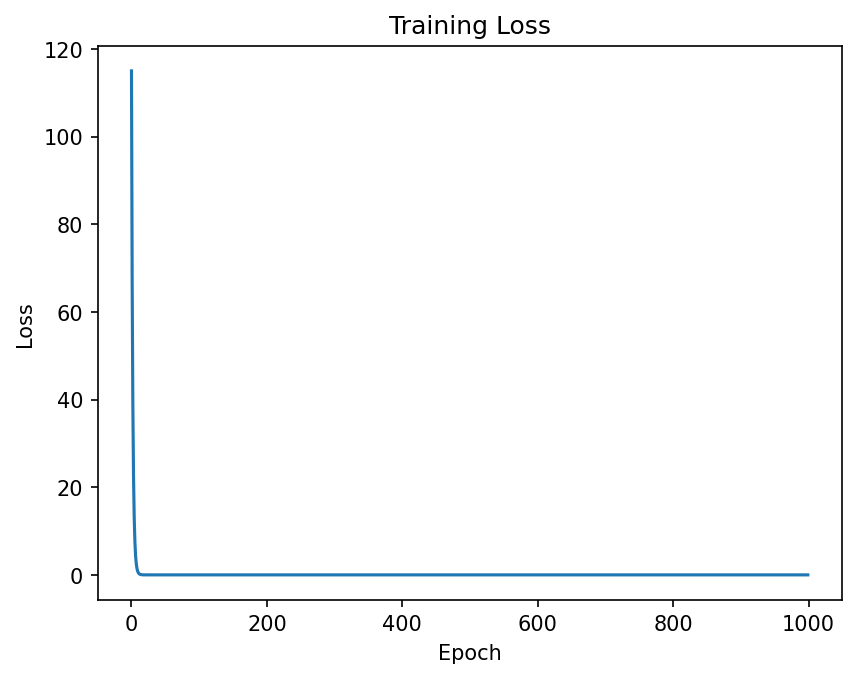

In [2]:
plt.plot(loss_history)

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Training Loss")

plt.show()

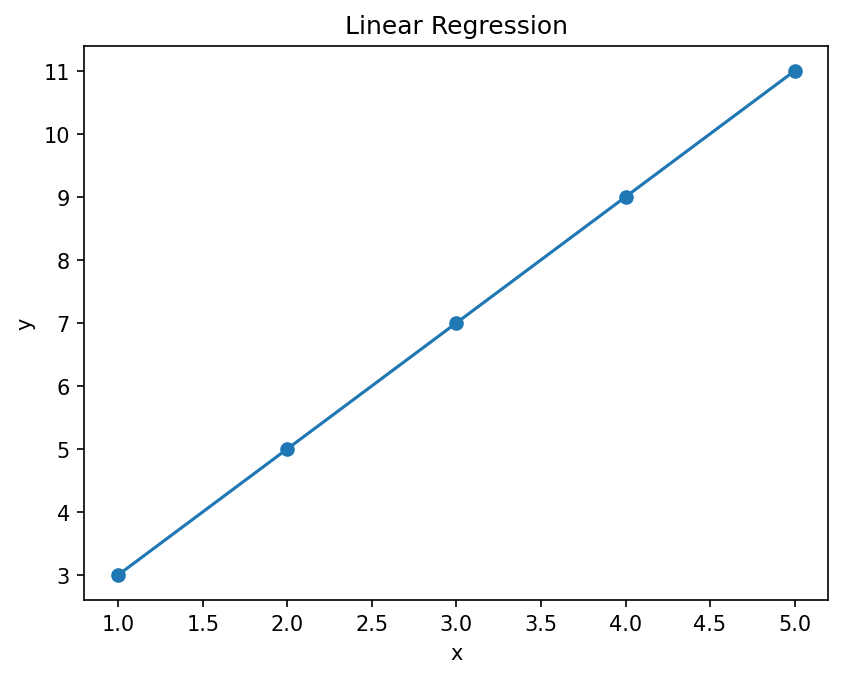

In [3]:
plt.scatter(x.numpy(), y.numpy())

with torch.no_grad():
    y_pred = model(x)

plt.plot(x.numpy(), y_pred.numpy())

plt.xlabel("x")
plt.ylabel("y")
plt.title("Linear Regression")

plt.show()

In [4]:
t = torch.tensor([[6.0]])

with torch.no_grad():
    y_guess = model(t)

print("x =", t.item())
print("prediction =", y_guess.item())

x = 6.0
prediction = 13.001672744750977


## 2.1 线性模型

前面几个 cell 是最早自己写的小练习（1 个特征、5 个样本），下面换成 `make_friedman1` 做正式实验：用 PyTorch 搭一个不含隐藏层的线性回归模型，自选评价指标并做可视化。

完整的结果表格与分析见 `2.1_实验报告.md`。

In [5]:
# 2.1-(1) 数据准备：生成数据 → 划分训练/验证/测试 → 标准化
import numpy as np
import torch
import torch.nn as nn
import matplotlib.pyplot as plt

from sklearn.datasets import make_friedman1
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

SEED = 42
torch.manual_seed(SEED)
np.random.seed(SEED)

# 1. 生成数据
X, y = make_friedman1(
    n_samples=1500,
    n_features=10,
    noise=1.0,
    random_state=42
)

print("X:", X.shape, "  y:", y.shape)
print("y: min=%.3f  max=%.3f  mean=%.3f  std=%.3f"
      % (y.min(), y.max(), y.mean(), y.std()))

# 2. 划分训练 / 验证 / 测试
X_train, X_tmp, y_train, y_tmp = train_test_split(
    X, y, test_size=0.4, random_state=SEED
)
X_val, X_test, y_val, y_test = train_test_split(
    X_tmp, y_tmp, test_size=0.5, random_state=SEED
)
print("train %d / val %d / test %d" % (len(X_train), len(X_val), len(X_test)))

# 3. 标准化（scaler 只用训练集 fit）
x_scaler = StandardScaler().fit(X_train)
y_scaler = StandardScaler().fit(y_train.reshape(-1, 1))


def to_tensor(a):
    return torch.tensor(np.asarray(a), dtype=torch.float32)


X_train_t = to_tensor(x_scaler.transform(X_train))
X_val_t = to_tensor(x_scaler.transform(X_val))
X_test_t = to_tensor(x_scaler.transform(X_test))

y_train_t = to_tensor(y_scaler.transform(y_train.reshape(-1, 1)))
y_val_t = to_tensor(y_scaler.transform(y_val.reshape(-1, 1)))
y_test_t = to_tensor(y_scaler.transform(y_test.reshape(-1, 1)))

print("X_train:", tuple(X_train_t.shape), "  y_train:", tuple(y_train_t.shape))


X: (1500, 10)   y: (1500,)
y: min=0.526  max=28.942  mean=14.296  std=4.879
train 900 / val 300 / test 300
X_train: (900, 10)   y_train: (900, 1)


In [6]:
# 2.1-(2) 模型：单层线性回归，不含隐藏层
class LinearRegressor(nn.Module):
    def __init__(self, in_features):
        super().__init__()
        self.linear = nn.Linear(in_features, 1)

    def forward(self, x):
        return self.linear(x)


lin_model = LinearRegressor(in_features=X.shape[1])

print(lin_model)
print("参数量: %d" % sum(p.numel() for p in lin_model.parameters()))


LinearRegressor(
  (linear): Linear(in_features=10, out_features=1, bias=True)
)
参数量: 11


In [7]:
# 2.1-(3) 训练：Adam + MSE，每个 epoch 在验证集上评估，按验证集挑最优参数
from torch.utils.data import TensorDataset, DataLoader

BATCH_SIZE = 64
EPOCHS = 200
LR = 0.01

train_loader = DataLoader(
    TensorDataset(X_train_t, y_train_t),
    batch_size=BATCH_SIZE,
    shuffle=True
)

criterion = nn.MSELoss()
optimizer = torch.optim.Adam(lin_model.parameters(), lr=LR)

train_hist = []
val_hist = []
best_val = float("inf")
best_state = None

for epoch in range(EPOCHS):
    lin_model.train()
    running = 0.0
    for xb, yb in train_loader:
        optimizer.zero_grad()
        loss = criterion(lin_model(xb), yb)
        loss.backward()
        optimizer.step()
        running += loss.item() * len(xb)

    train_loss = running / len(X_train_t)

    lin_model.eval()
    with torch.no_grad():
        val_loss = criterion(lin_model(X_val_t), y_val_t).item()

    train_hist.append(train_loss)
    val_hist.append(val_loss)

    if val_loss < best_val:
        best_val = val_loss
        best_state = {k: v.clone() for k, v in lin_model.state_dict().items()}

    if (epoch + 1) % 40 == 0:
        print("epoch %3d/%d  train MSE %.4f   val MSE %.4f"
              % (epoch + 1, EPOCHS, train_loss, val_loss))

lin_model.load_state_dict(best_state)

print("训练完成，最优验证 MSE（标准化空间）= %.4f" % best_val)
print("weight:", np.round(lin_model.linear.weight.detach().numpy().ravel(), 3))
print("bias: %.4f" % lin_model.linear.bias.item())


epoch  40/200  train MSE 0.2791   val MSE 0.2700
epoch  80/200  train MSE 0.2802   val MSE 0.2705
epoch 120/200  train MSE 0.2813   val MSE 0.2722
epoch 160/200  train MSE 0.2789   val MSE 0.2696
epoch 200/200  train MSE 0.2773   val MSE 0.2708
训练完成，最优验证 MSE（标准化空间）= 0.2627
weight: [ 0.372  0.41  -0.004  0.569  0.33  -0.024  0.023  0.027  0.017  0.029]
bias: -0.0101


In [8]:
# 2.1-(4) 评价指标：MSE / RMSE / MAE / R²（都换算回原始尺度）
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score


def predict_original(model, X_t):
    model.eval()
    with torch.no_grad():
        pred_std = model(X_t).numpy()
    return y_scaler.inverse_transform(pred_std).ravel()


def regression_metrics(y_true, y_pred, name):
    mse = mean_squared_error(y_true, y_pred)
    rmse = mse ** 0.5
    mae = mean_absolute_error(y_true, y_pred)
    r2 = r2_score(y_true, y_pred)
    print("[%s]\n    MSE  = %.4f\n    RMSE = %.4f\n    MAE  = %.4f\n    R2   = %.4f"
          % (name, mse, rmse, mae, r2))
    return dict(model=name, MSE=mse, RMSE=rmse, MAE=mae, R2=r2)


pred_train = predict_original(lin_model, X_train_t)
pred_val = predict_original(lin_model, X_val_t)
pred_test = predict_original(lin_model, X_test_t)

print("y 的标准差（原始尺度）= %.4f\n" % y_test.std())

linear_train = regression_metrics(y_train, pred_train, "线性模型 - 训练集")
linear_val = regression_metrics(y_val, pred_val, "线性模型 - 验证集")
linear_test = regression_metrics(y_test, pred_test, "线性模型 - 测试集")

print("\n最终测试结果：")
print("    RMSE = %.4f   MAE = %.4f   R2 = %.4f"
      % (linear_test["RMSE"], linear_test["MAE"], linear_test["R2"]))


y 的标准差（原始尺度）= 4.8284

[线性模型 - 训练集]
    MSE  = 6.6981
    RMSE = 2.5881
    MAE  = 2.0506
    R2   = 0.7202
[线性模型 - 验证集]
    MSE  = 6.2873
    RMSE = 2.5074
    MAE  = 2.0107
    R2   = 0.7358
[线性模型 - 测试集]
    MSE  = 5.3770
    RMSE = 2.3188
    MAE  = 1.8174
    R2   = 0.7694

最终测试结果：
    RMSE = 2.3188   MAE = 1.8174   R2 = 0.7694


图已保存为 q2_1_linear_results.png


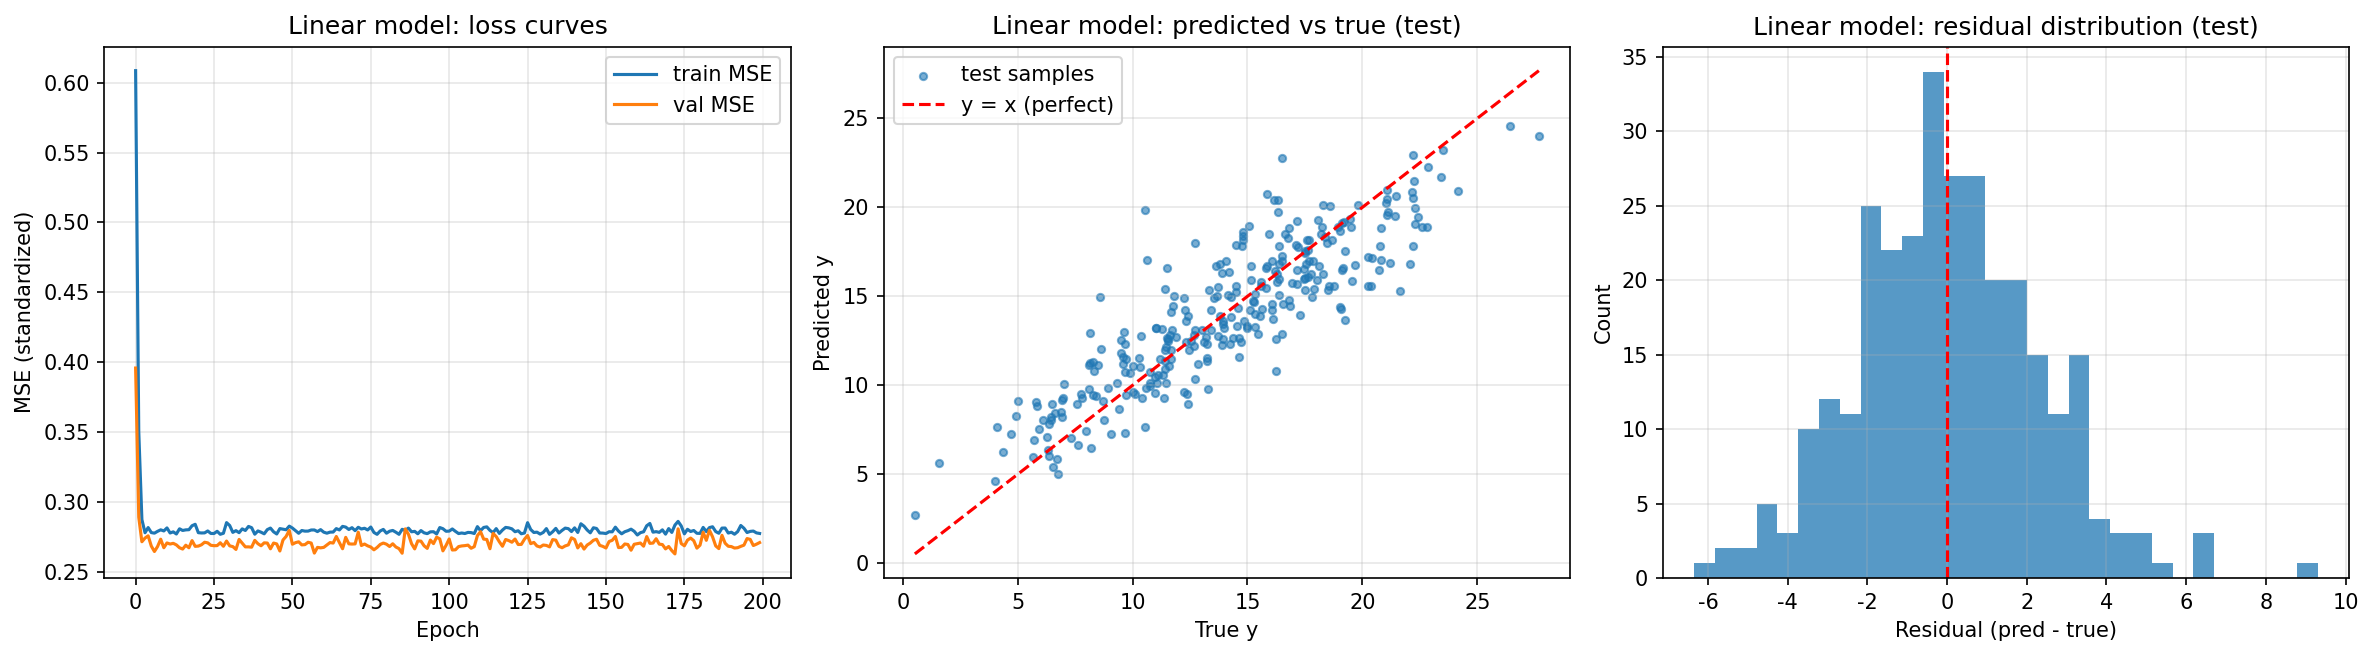

In [9]:
# 2.1-(5) 可视化：训练曲线 / 预测值 vs 真实值 / 残差分布
plt.rcParams["axes.unicode_minus"] = False

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))

axes[0].plot(train_hist, label="train MSE")
axes[0].plot(val_hist, label="val MSE")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("MSE (standardized)")
axes[0].set_title("Linear model: loss curves")
axes[0].legend()
axes[0].grid(alpha=0.3)

axes[1].scatter(y_test, pred_test, s=12, alpha=0.6, label="test samples")
lim = [min(y_test.min(), pred_test.min()), max(y_test.max(), pred_test.max())]
axes[1].plot(lim, lim, "r--", label="y = x (perfect)")
axes[1].set_xlabel("True y")
axes[1].set_ylabel("Predicted y")
axes[1].set_title("Linear model: predicted vs true (test)")
axes[1].legend()
axes[1].grid(alpha=0.3)

residual = pred_test - y_test
axes[2].hist(residual, bins=30, alpha=0.75)
axes[2].axvline(0, color="r", linestyle="--")
axes[2].set_xlabel("Residual (pred - true)")
axes[2].set_ylabel("Count")
axes[2].set_title("Linear model: residual distribution (test)")
axes[2].grid(alpha=0.3)

plt.tight_layout()
plt.savefig("q2_1_linear_results.png", dpi=150, bbox_inches="tight")
plt.show()
print("图已保存为 q2_1_linear_results.png")
